# Решающие деревья

#  I. Немного решающих деревьев
##### Задача 1. Построение "среднего" алгоритма
В этом задании вам нужно построить графики, демонстрирующие, как алгоритм аппроксимирует истинную зависимость в данных и как он меняется в зависимости от гиперпараметров метода обучения.

In [126]:
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor, BaggingRegressor, BaggingClassifier
import numpy as np
import pandas as pd
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from matplotlib import pyplot as plt
from sklearn.tree._criterion import Gini
from sklearn.preprocessing import LabelEncoder, OrdinalEncoder
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import accuracy_score, f1_score
%matplotlib inline

In [127]:
def f(x):
    return np.sin(x)   # истинная зависимость в данных
sample_size = 100      # длина выборки
samples_num = 20       # количество выборок
linspace = np.linspace(0, 7, 1000)  # точки для построения графиков

__1. (2 балла)__
1. Сгенерируйте выборку $x$ из одномерного экспоненциального распределения (np.random.exponential) длины sample_size.
1. Создайте вектор целевых переменных $y$ как сумму $f(x)$ и случайного шума, сгенерированного из равномерного распределения на отрезке $[-1, 1]$ (np.random.uniform).
1. Обучите DecisionTreeRegressor с параметрами по умолчанию на полученной выборке и сделайте предсказания для объектов из linspace.
1. Постройте два графика на одном рисунке: $f(x)$ и зависимость, восстановленную решающим деревом.

    Рекомендация: не забудьте, что все методы обучения в sklearn требуют на вход двумерную матрицу объекты-признаки. Сделать такую из одномерного вектора можно добавлением мнимых осей (np.newaxis).

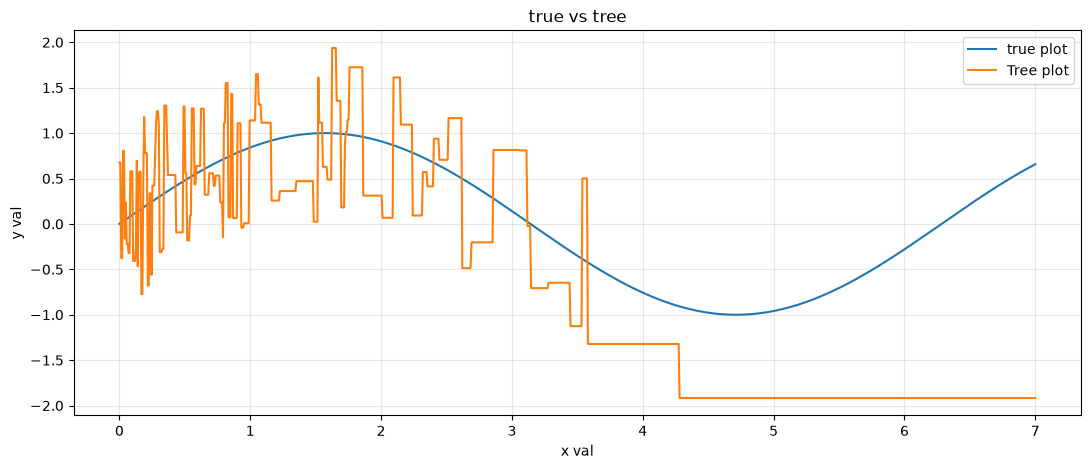

In [128]:
x_train = np.random.exponential(size=sample_size).reshape(-1, 1)
y_train = f(x_train) + np.random.uniform(-1, 1, size=sample_size).reshape(-1, 1)  
model = DecisionTreeRegressor().fit(x_train, y_train)

x_test = linspace.reshape(-1, 1)
y_test = f(x_test)
y_pred = model.predict(x_test)

figure, axis = plt.subplots(1, 1, figsize = (13, 5))
axis.plot(x_test, y_test, label="true plot")
axis.plot(x_test, y_pred, label="Tree plot")
axis.set_xlabel("x val")
axis.set_ylabel("y val")
axis.set_title("true vs tree")
axis.grid(True, alpha=0.3)
axis.legend()

plt.show()

__2. (2 балл)__

Повторите первые 3 шага, описанные выше, samples_num раз. На одном графике для каждого обученного решающего дерева визуализируйте восстановленную им зависимость (рекомендуется все такие линии рисовать полупрозрачными и серым цветом: plt.plot(...... color="gray", alpha=0.5)).  На этом же графике изобразите истинную зависимость f(x) (красным цветом: color="red") и усредненную по всем деревьям восстановленную зависимость (черным цветом: color="black").    

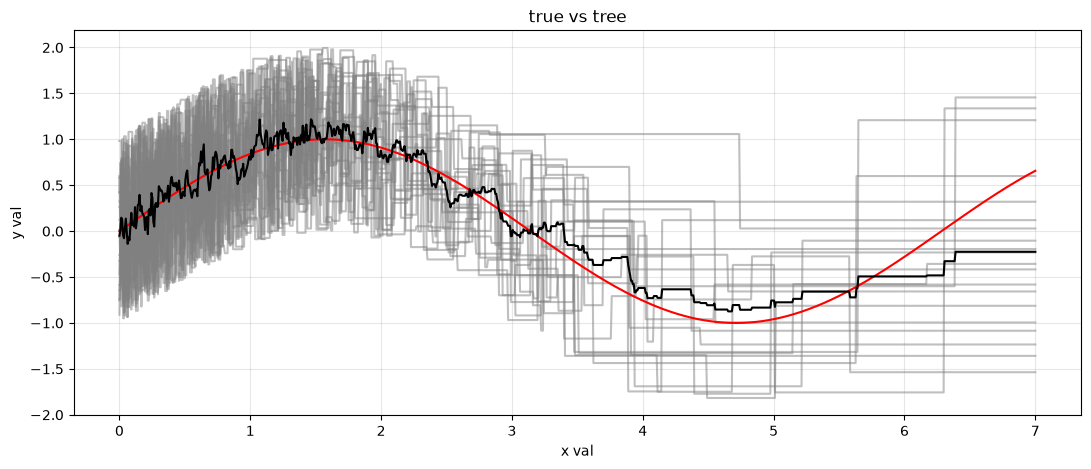

In [129]:
figure, axis = plt.subplots(1, 1, figsize = (13, 5))
x_test = linspace.reshape(-1, 1)
y_test = f(x_test)
y_preds = []

for _ in range(samples_num):
    x_train = np.random.exponential(size=sample_size).reshape(-1, 1)
    y_train = f(x_train) + np.random.uniform(-1, 1, size=sample_size).reshape(-1, 1)  
    model = DecisionTreeRegressor().fit(x_train, y_train)
    
    y_pred = model.predict(x_test)
    y_preds.append(y_pred)
    axis.plot(x_test, y_pred, label="Tree plot", alpha = 0.5, color="gray")

y_preds = np.array(y_preds)
y_preds = y_preds.mean(axis = 0)

axis.plot(x_test, y_test, label="true plot", color="red")
axis.plot(x_test, y_preds, label="true plot", color="black")
axis.set_xlabel("x val")
axis.set_ylabel("y val")
axis.set_title("true vs tree")
axis.grid(True, alpha=0.3)

plt.show()

**Ответ:**

### II. Решающие деревья чужими руками

#### Задача 3.
В этой части вам нужно посмотреть на класс написанный за вас для обучения решающего дерева в задаче бинарной классификации с возможностью обработки вещественных и категориальных признаков.

__8. (1 балл)__

Загрузите таблицу [students.csv](https://drive.google.com/file/d/0B2zoFVYw1rN3a0d0Zm43TzQ4aUU/view?usp=sharing) (это немного преобразованный датасет [User Knowledge](https://archive.ics.uci.edu/ml/datasets/User+Knowledge+Modeling)). В ней признаки объекта записаны в первых пяти столбцах, а в последнем записана целевая переменная (класс: 0 или 1). Постройте на одном изображении пять кривых "порог — значение критерия Джини" для всех пяти признаков. Отдельно визуализируйте scatter-графики "значение признака — класс" для всех пяти признаков.

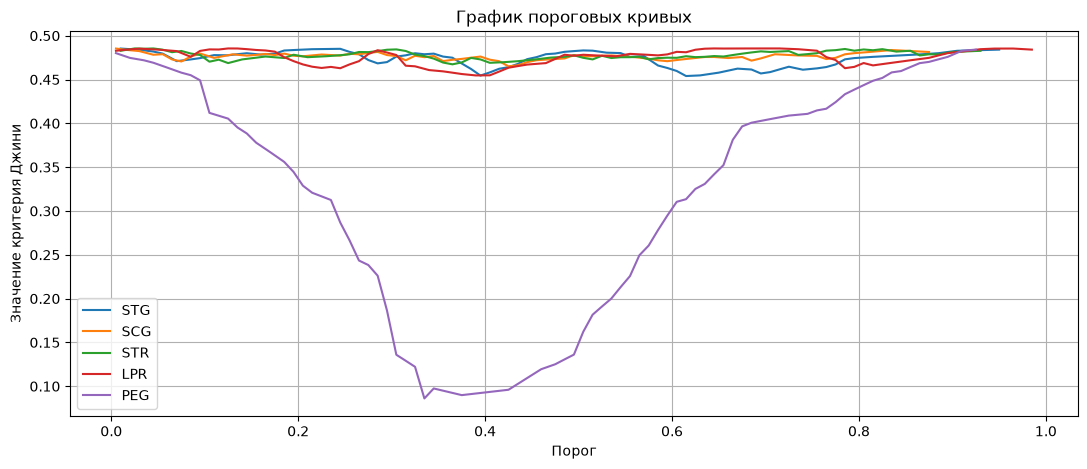

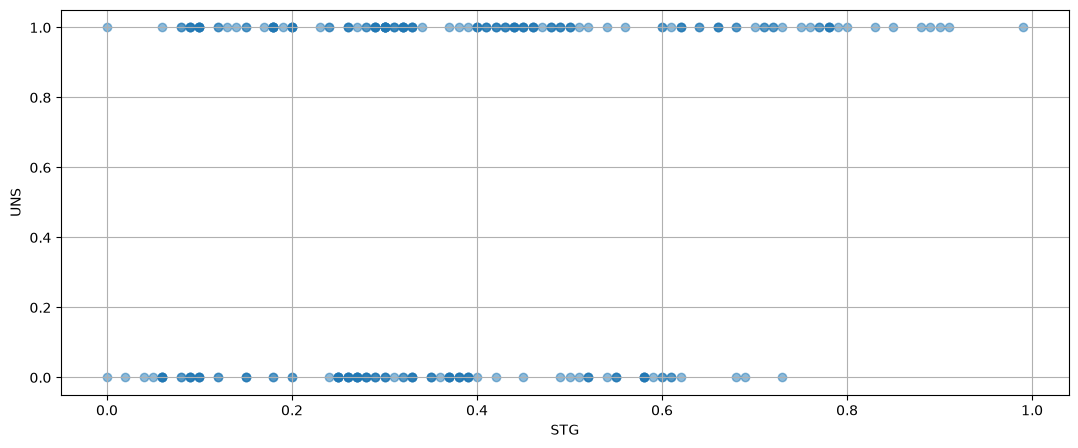

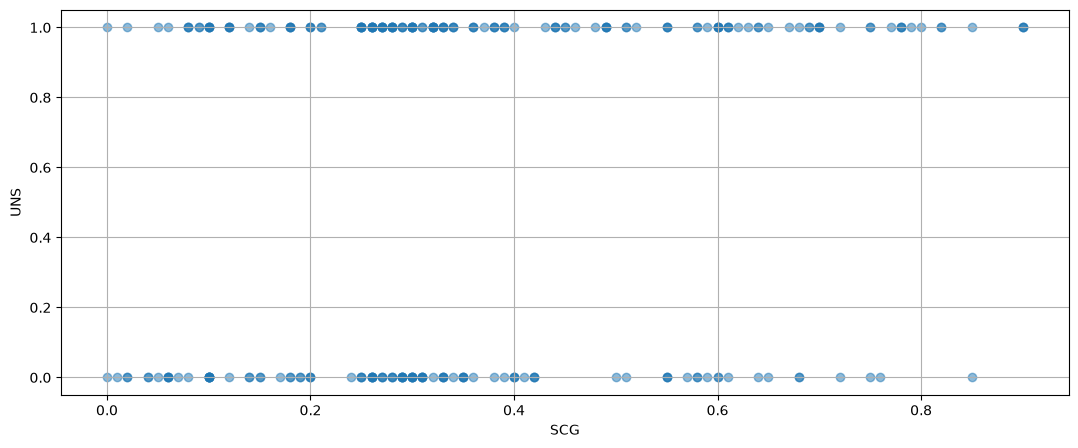

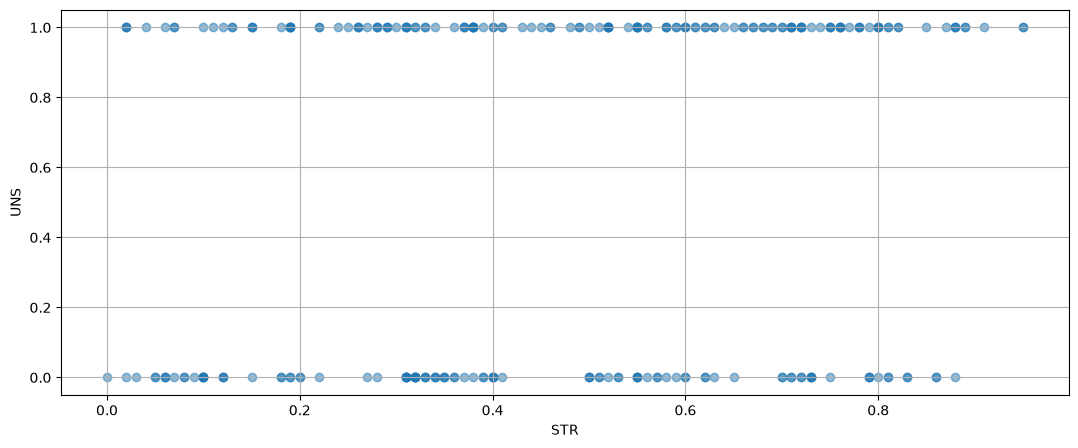

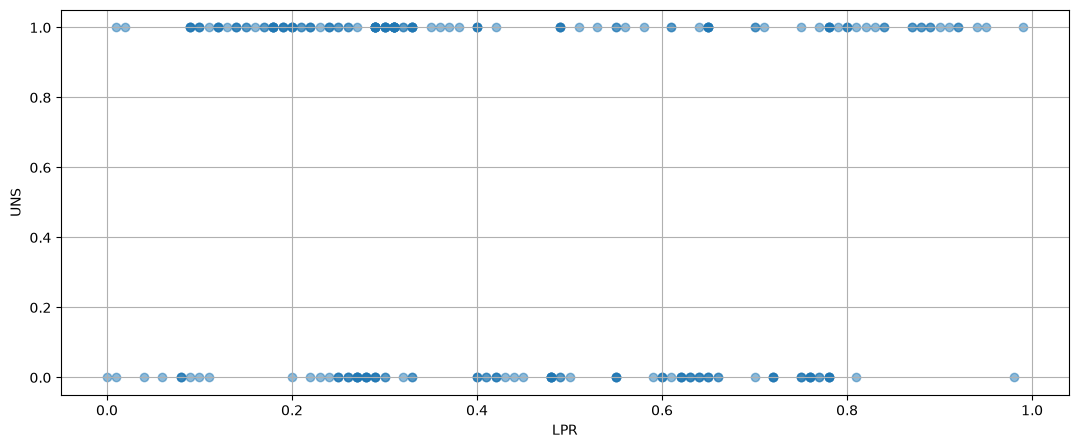

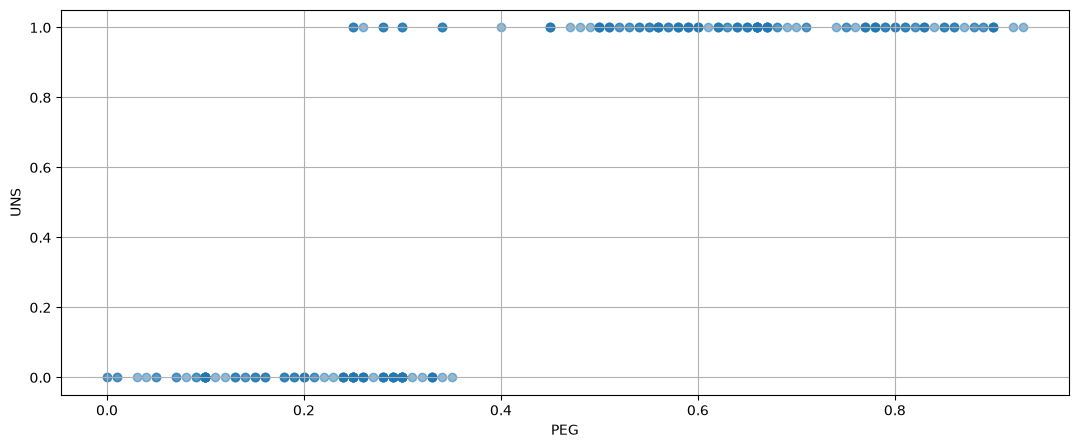

In [130]:
def gini(x: np.array):
    p = np.unique_counts(x).counts / x.size
    return np.sum(p * (1 - p))

def best_split(features: np.array, target : np.array):
    uvals = np.sort(np.unique(features))
    ts = (uvals[:-1] + uvals[1:]) / 2

    ginis = []
    for t in ts:
        ltarget = target[features <= t]
        rtarget = target[features > t]

        criterion = (len(ltarget) / len(target)) * gini(ltarget) + (len(rtarget) / len(target)) * gini(rtarget)
        ginis.append(criterion)

    return ts, ginis

import pandas as pd
data = pd.read_csv('students.csv')
features = data.drop("UNS", axis=1)
target = data["UNS"]

figure, axis = plt.subplots(1, 1, figsize = (13, 5))

for col in features.columns:
    ts, ginis = best_split(features[col].values, target.values)
    axis.plot(ts, ginis, label=col)

axis.set_title("График пороговых кривых")
axis.set_ylabel("Значение критерия Джини")
axis.set_xlabel("Порог")
axis.grid(True)
axis.legend()
plt.show()


for col in features.columns:
    figure, axis = plt.subplots(1, 1, figsize = (13, 5))
    axis.scatter(features[col], target, alpha=0.5)
    axis.set_xlabel(col)
    axis.set_ylabel("UNS")
    axis.grid(True)
    plt.show()

__9. (1 балл)__

Исходя из кривых значений критерия Джини, по какому признаку нужно производить деление выборки на два поддерева? Согласуется ли этот результат с визуальной оценкой scatter-графиков? Как бы охарактеризовали вид кривой для "хороших" признаков, по которым выборка делится почти идеально? Чем отличаются кривые для признаков, по которым деление практически невозможно?

**Ответ:** нужно проводить деление по PEG, данные результат исходит из формы пороговой кривой и визуальной оценкой scatter графике, где точки чётко линейно разделимы. У хороших признаков пороговая кривая должна иметь вид функции |x| или что-то в этом духе, где кривая строго убывает, а потом строго возрастает, в точке минимума она достигает оптимального порога. Деление практически не возможно по признакам, пороговые кривые которых около паралельны Ox т.к. от изменения порога у таких признаков критерий не меняется.

__10. (1 балл)__

Протестируйте свое решающее дерево на датасете [mushrooms](https://archive.ics.uci.edu/ml/datasets/Mushroom). Вам нужно скачать таблицу agaricus-lepiota.data (из [Data Folder](https://archive.ics.uci.edu/ml/machine-learning-databases/mushroom/)), прочитать ее с помощью pandas, применить к каждому столбцу LabelEncoder (из sklearn), чтобы преобразовать строковые имена категорий в натуральные числа. Первый столбец — это целевая переменная (e — edible, p — poisonous) Мы будем измерять качество с помощью accuracy, так что нам не очень важно, что будет классом 1, а что — классом 0. Обучите решающее дерево на половине случайно выбранных объектов (признаки в датасете категориальные) и сделайте предсказания для оставшейся половины. Вычислите accuracy.

У вас должно получиться значение accuracy, равное единице (или очень близкое к единице), и не очень глубокое дерево.

In [131]:
ore = OrdinalEncoder()
lae = LabelEncoder()

df = pd.read_csv("msh.csv", sep=",", names=["target", "f1", "f2", "f3", "f4", "f5", "f6", "f7", "f8", "f9", "f10", "f11", "f12", "f13", "f14", "f15", "f16", "f17", "f18", "f19", "f20", "f21", "f22"])

x = df.drop("target", axis=1)
y = df["target"]

y = lae.fit_transform(y)
x = ore.fit_transform(x)

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.5)

model = DecisionTreeClassifier(max_depth=7).fit(x_train, y_train)
pred = model.predict(x_test)
score = accuracy_score(y_test, pred)
print(score)

1.0


### IIII. Композиции деревьев
#### Задача 4. Сравнение композиционных методов над решающими деревьями
__11. (1 балл)__

Загрузите датасет из соревнования [BNP Paribas Cardif Claims Management](https://www.kaggle.com/c/bnp-paribas-cardif-claims-management/leaderboard). Возьмите из него первые 10к объектов, оставьте только вещественные признаки, а пропуски замените нулями. Разбейте выборку на обучение и контроль в соотношении 7:3.

1. С помощью cross_val_score с cv=3 оцените качество (accuracy) следующих классификаторов на обучающей выборке:
    * DecisionTreeClassifier
    * BaggingClassifier со 100 деревьями
    * RandomForestClassifier со 100 деревьями
    
Значение получается шумное, но в целом у вас должно получиться, что качество возрастает с каждым следующим алгоритмом (если это не так, то посмотрите как ведут себя алгоритмы с разными сидами в кроссвалидации и самих алгоритмах). Этот пример демонстрирует, что RandomForest — это более сложный алгоритм, чем бэггинг.

In [132]:
df = pd.read_csv("train.csv", index_col="ID", sep=",")
df.fillna(0)
df.drop(["v3", "v22", "v24", "v30", "v31", "v47", "v52", "v56", "v66", "v71", "v74", "v75", "v79", "v91", "v107", "v110", "v112", "v113", "v125"], axis = 1, inplace=True)
df = df[:10000]
x = df.drop("target", axis=1)
y = df["target"]

x_train, x_test, y_train, y_test = train_test_split(x, y, train_size=0.7)

model1 = DecisionTreeClassifier(max_depth=8).fit(x_train, y_train)
model2 = BaggingClassifier().fit(x_train, y_train)
model3 = RandomForestClassifier(n_estimators=500, max_depth=10, n_jobs=-1).fit(x_train, y_train)

pred1 = model1.predict(x_test)
pred2 = model2.predict(x_test)
pred3 = model3.predict(x_test)

score1 = accuracy_score(y_test, pred1)
score2 = accuracy_score(y_test, pred2)
score3 = accuracy_score(y_test, pred3)

print(score1, score2, score3)

0.7273333333333334 0.7073333333333334 0.7503333333333333


#### Задача 5. Число деревьев в случайном лесе
В этой задаче мы рассмотрим, переобучаются ли композиционные алгоритмы с увеличением числа деревьев.

__12. (1 балл)__

Переберите значения от 20 до 1000-5000 деревьев с шагом 20, посчитайте accuracy на тестовой выборке для каждого числа деревьев и постройте график зависимости качества от числа деревьев.

Рекомендация.

Если каждый раз обучать RandomForest с нуля, придётся обучить в общей сумме $20 + 200 + \ldots + 5000$ деревьев.
Однако, как мы знаем, деревья в случайных лесах строятся независимо и параллельно, поэтому можно обучить всего 5000 деревьев.

Для этого в при создании объекта класса RandomForestClassifier нужно указать в том числе warm_start=True. Затем обучить алгоритм с помощью метода fit, использовать метод predict для классификации. После этого с помощью метода set_params изменить параметр n_estimators. Если к полученному объекту применить метод fit, внутри него будет обучаться только недостающее число деревьев.

Переобучается ли случайный лес с увеличением числа деревьев?

[]

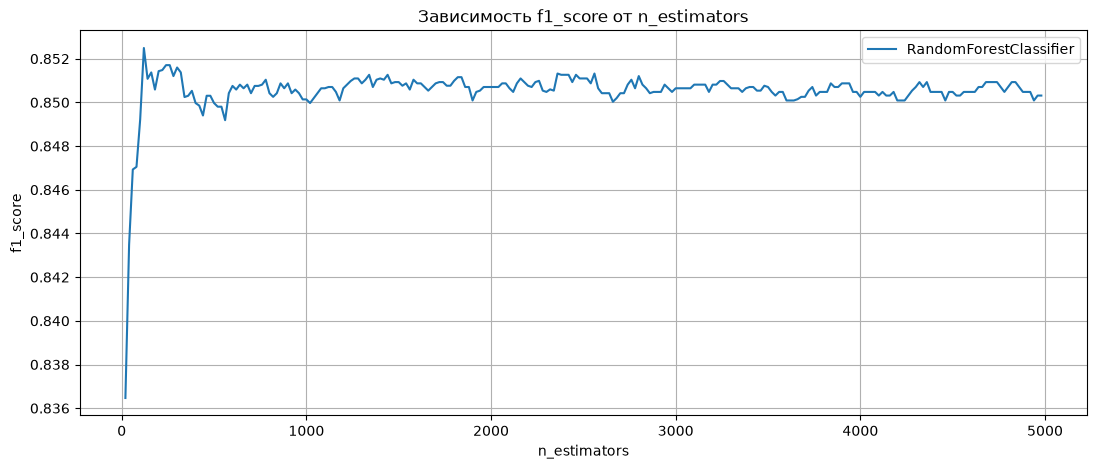

In [133]:
scores = []

model = RandomForestClassifier(n_estimators=20, warm_start=True, n_jobs=-1).fit(x_train, y_train)
pred = model.predict(x_test)
score = f1_score(y_test, pred)
scores.append(score)

for n in range(40, 5000, 20):
    model.set_params(n_estimators=n).fit(x_train, y_train)
    pred = model.predict(x_test)
    score = f1_score(y_test, pred)
    scores.append(score)

figure, axis = plt.subplots(1, 1, figsize=(13, 5))
axis.plot(list(range(20, 5000, 20)), scores, label="RandomForestClassifier")
axis.set_xlabel("n_estimators")
axis.set_ylabel("f1_score")
axis.set_title("Зависимость f1_score от n_estimators")
axis.grid(True)
axis.legend()
plt.plot()